# Семинар 12, часть 2. Понижение размерности: лица, Kernel PCA, t-SNE

В первой части мы разобрали PCA по шагам. Он делает два упрощения:

1. **не смотрит на целевую переменную** — ищет направления наибольшего разброса, а не наибольшей пользы для задачи;
2. **строит линейные комбинации признаков** — поэтому видит только «прямолинейную» структуру.

Первое упрощение на практике часто не мешает: данные нередко устроены так, что основная структура лежит в пространстве меньшей размерности независимо от целевой переменной. Сегодня посмотрим, как PCA работает на изображениях лиц, а затем снимем второе ограничение: Kernel PCA и t-SNE находят нелинейную структуру.

План:

1. Когда PCA находит хорошие направления, а когда нет.
2. PCA на фотографиях лиц: «собственные лица», сжатие, классификация.
3. Kernel PCA.
4. t-SNE: визуализация цифр, роль perplexity, что можно и чего нельзя читать по картинке.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA, KernelPCA
from sklearn.datasets import make_circles, make_moons, make_blobs, load_digits

plt.rcParams['figure.figsize'] = [10, 7]

## 1. PCA на плоскости

Функция `PCA_show` рисует точки и главные направления. Длина стрелки — два стандартных отклонения данных вдоль компоненты, то есть $2\sqrt{\lambda}$: так стрелка соразмерна разбросу точек, который мы видим на графике.

In [2]:
def PCA_show(data, ax=None, title=None):
    ax = ax or plt.gca()
    ax.scatter(data[:, 0], data[:, 1], alpha=0.4, s=8)
    dec = PCA().fit(data)
    for comp, var in zip(dec.components_, dec.explained_variance_):
        vec = comp * 2 * np.sqrt(var)
        ax.arrow(*dec.mean_, *vec, width=0.05, color='red', length_includes_head=True)
    ax.set_aspect('equal', adjustable='datalim')
    if title:
        ax.set_title(title + f'\nдоли дисперсии: {dec.explained_variance_ratio_.round(2)}')

Сгенерируем облако из двумерного нормального распределения с дисперсиями 4 и 1 по осям, а потом повернём его на 30°. PCA должен найти оси облака в обоих случаях.

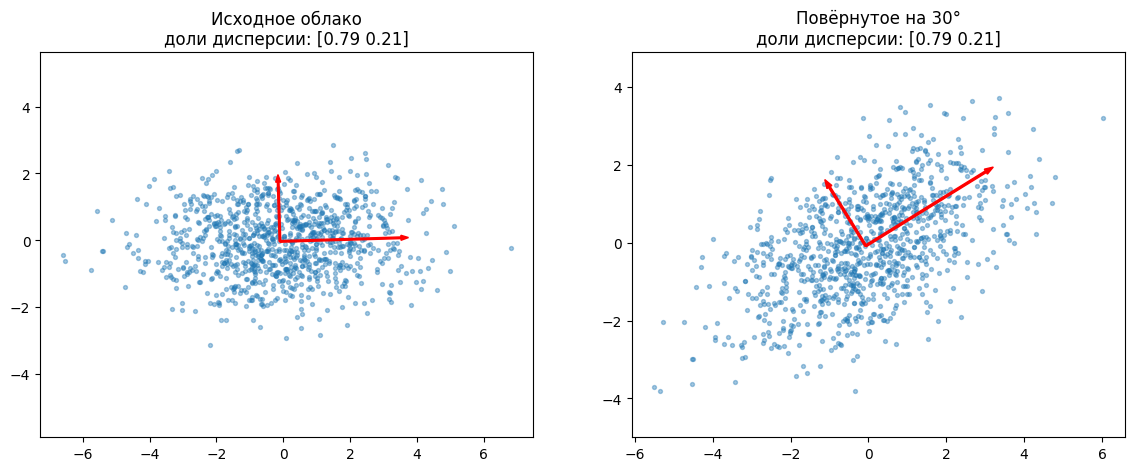

Компоненты повёрнутого облака:
 [[ 0.851  0.526]
 [-0.526  0.851]]


In [3]:
rng = np.random.default_rng(314512)
data_1 = rng.multivariate_normal(mean=[0, 0], cov=[[4, 0], [0, 1]], size=1000)

angle = np.pi / 6
rotate = np.array([[np.cos(angle), -np.sin(angle)],
                   [np.sin(angle),  np.cos(angle)]])
data_2 = data_1 @ rotate.T

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
PCA_show(data_1, axes[0], 'Исходное облако')
PCA_show(data_2, axes[1], 'Повёрнутое на 30°')
plt.show()
print('Компоненты повёрнутого облака:\n', PCA().fit(data_2).components_.round(3))

В обоих случаях PCA находит оси облака, доли дисперсии одинаковые (около 0,8 и 0,2 — как $4/5$ и $1/5$). Поворот данных просто поворачивает компоненты: первая компонента повёрнутого облака направлена под углом 30° — $(\cos 30°, \sin 30°) \approx (0{,}87; 0{,}5)$ с точностью до знака.

Теперь четыре других набора данных.

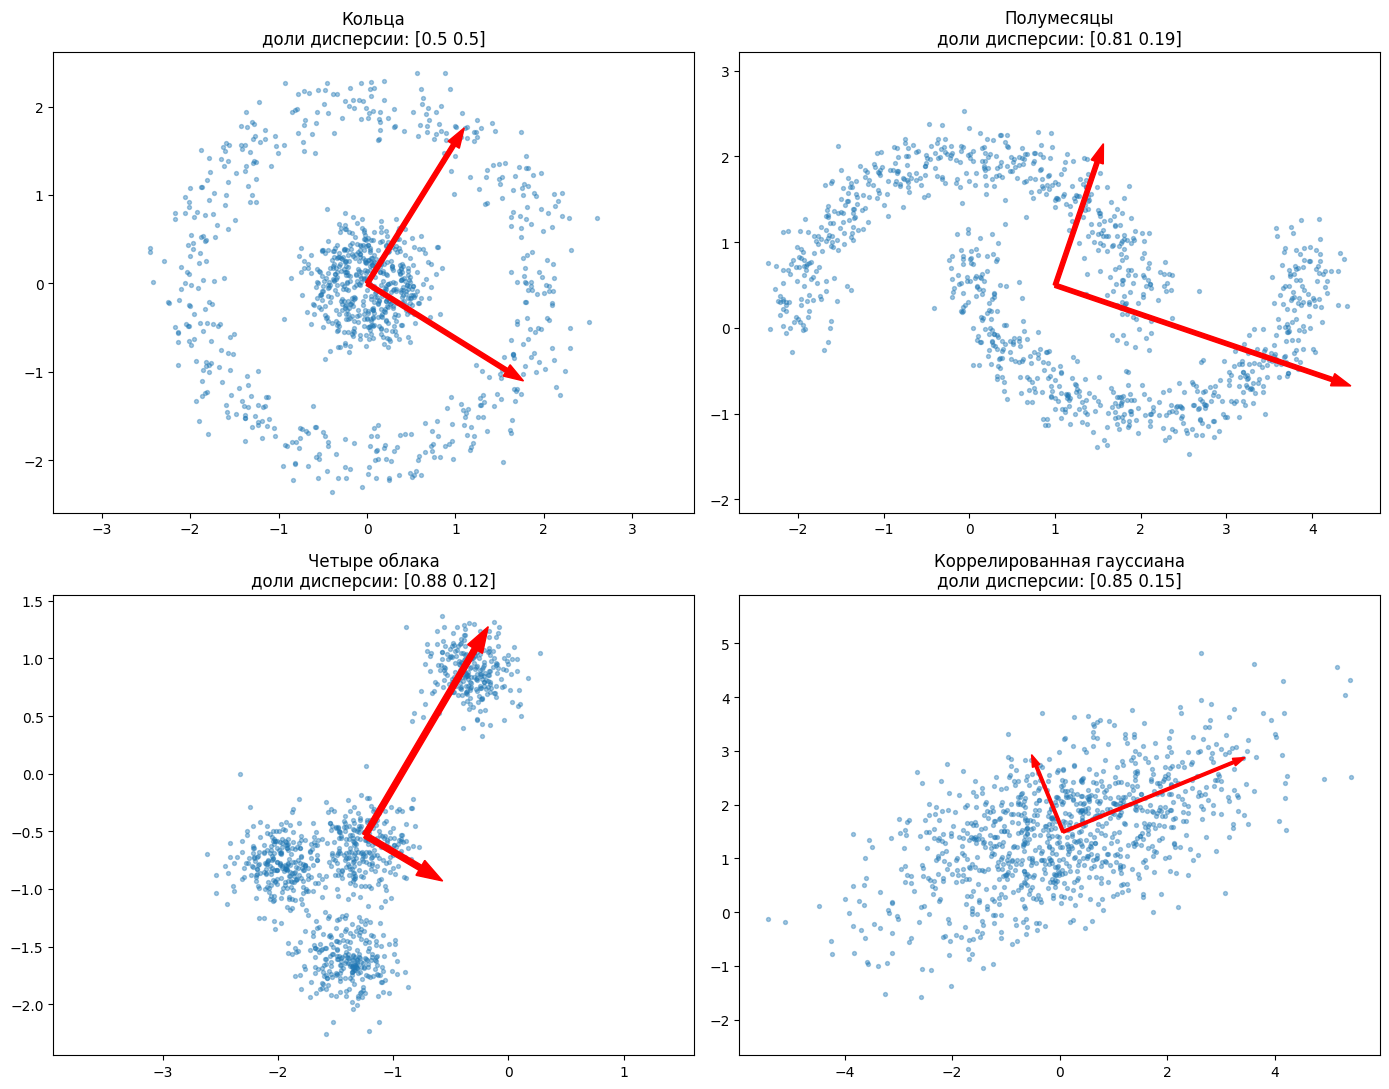

In [4]:
rng = np.random.default_rng(54242)
data_bad = [
    ('Кольца', make_circles(n_samples=1000, factor=0.2, noise=0.1, random_state=0)[0] * 2),
    ('Полумесяцы', make_moons(n_samples=1000, noise=0.1, random_state=0)[0] * 2),
    ('Четыре облака', make_blobs(n_samples=1000, centers=4, random_state=1)[0] / 5),
    ('Коррелированная гауссиана', rng.multivariate_normal(mean=[0, 1.5], cov=[[3, 1], [1, 1]], size=1000)),
]
fig, axes = plt.subplots(2, 2, figsize=(14, 11))
for ax, (name, data) in zip(axes.ravel(), data_bad):
    PCA_show(data, ax, name)
plt.tight_layout()
plt.show()

**Вопрос.** На каких из четырёх наборов главные направления осмысленно описывают данные, а на каких нет и почему?

<details>
<summary><b>Показать ответ</b></summary>

- **Коррелированная гауссиана** — PCA работает идеально: облако эллиптическое, и его оси действительно описывают данные.
- **Кольца** — доли дисперсии почти равны (около 0,5 и 0,5): облако симметрично во все стороны, у него нет выделенного направления, и компоненты выбраны почти случайно. Главная структура — радиус — нелинейна, никакая прямая её не передаёт.
- **Полумесяцы** — PC1 идёт вдоль вытянутости облака, но классы различаются изгибом, а не положением вдоль прямой.
- **Четыре облака** — PCA описывает общий разброс, но не кластерную структуру: проекция на PC1 может накладывать облака друг на друга.

PCA хорошо работает, когда главная изменчивость данных линейна. Для изогнутых многообразий нужны нелинейные методы — Kernel PCA и t-SNE ниже.

</details>

## 2. Фотографии лиц

Датасет Olivetti: 400 фотографий 40 людей (по 10 на человека), 64 × 64 пикселя, то есть 4096 признаков — яркостей от 0 до 1. Пиксели в одних единицах, поэтому только центрируем: вычитаем «среднее лицо».

Датасет скачивается при первом запуске (около 1,5 МБ).

downloading Olivetti faces from https://ndownloader.figshare.com/files/5976027 to /root/scikit_learn_data
(400, 4096)


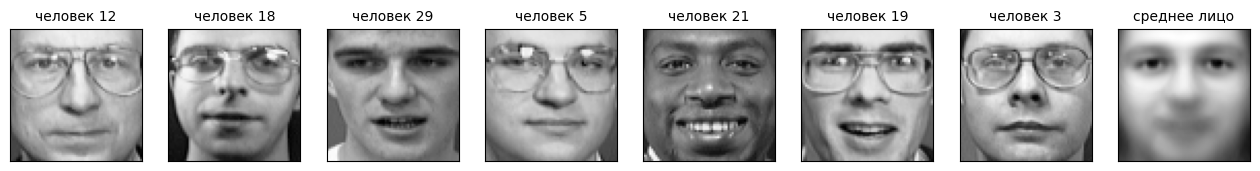

In [5]:
from sklearn.datasets import fetch_olivetti_faces

faces = fetch_olivetti_faces(shuffle=True, random_state=432540)
X_faces, y_faces = faces.data, faces.target
image_shape = (64, 64)
mean_face = X_faces.mean(axis=0)

def show_faces(images, titles=None, rows=1, cols=8, size=2):
    fig, axes = plt.subplots(rows, cols, figsize=(cols * size, rows * size * 1.1),
                             subplot_kw={'xticks': [], 'yticks': []})
    for i, ax in enumerate(np.ravel(axes)):
        ax.imshow(images[i].reshape(image_shape), cmap='gray')
        if titles is not None:
            ax.set_title(titles[i], fontsize=10)
    plt.show()

print(X_faces.shape)
show_faces(np.vstack([X_faces[:7], mean_face]), titles=[f'человек {t}' for t in y_faces[:7]] + ['среднее лицо'])

### 2.1 «Собственные лица»

Каждая главная компонента — вектор из 4096 чисел, то есть тоже картинка 64 × 64. Такие картинки называют eigenfaces — «собственные лица».

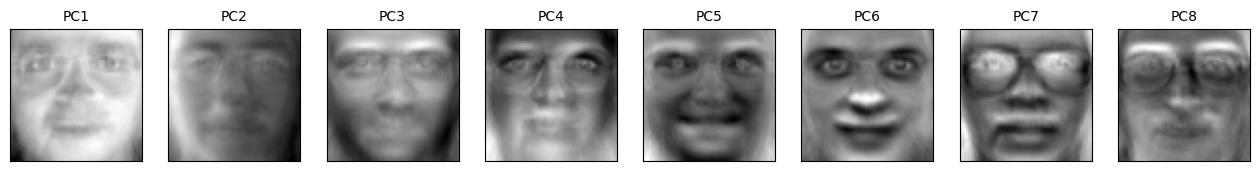

80 % дисперсии: 27 компонент из 400
90 % дисперсии: 66 компонент из 400
95 % дисперсии: 123 компонент из 400


In [6]:
pca_faces = PCA(random_state=0).fit(X_faces)     # PCA сам вычитает среднее

show_faces(pca_faces.components_[:8], titles=[f'PC{i + 1}' for i in range(8)])
cum = np.cumsum(pca_faces.explained_variance_ratio_)
for p in [0.8, 0.9, 0.95]:
    print(f'{int(p * 100)} % дисперсии: {np.argmax(cum >= p) + 1} компонент из {len(cum)}')

Первые компоненты похожи на размытые лица с разным освещением: PC1 и PC2 в основном описывают, откуда падает свет и насколько светлое лицо в целом. Дальше появляются детали — очки, брови, форма лица.

**Вопрос.** Компонент у PCA здесь не больше 400, хотя признаков 4096. Почему?

<details>
<summary><b>Показать ответ</b></summary>

Число ненулевых главных компонент не превышает ранга центрированной матрицы данных, а он не больше $\min(n - 1, d) = \min(399, 4096) = 399$: 400 точек вместе с их средним лежат в подпространстве размерности не больше 399. `sklearn` возвращает $\min(n, d) = 400$ компонент, но последняя из них имеет нулевую дисперсию. Это типичная ситуация для изображений: объектов меньше, чем признаков.

</details>

### 2.2 Сжатие

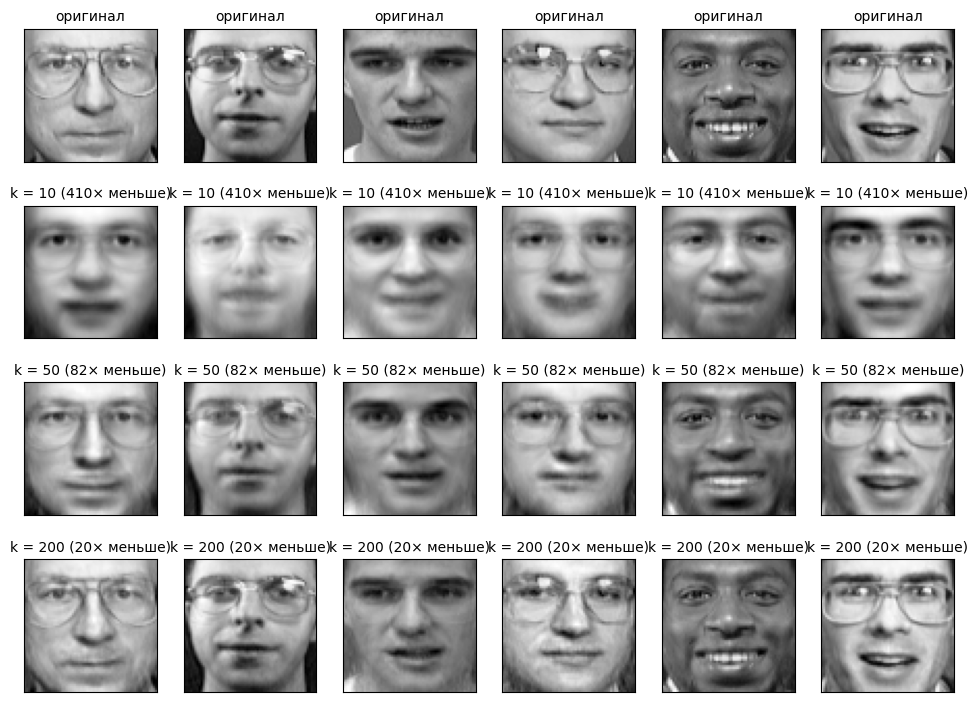

In [7]:
idx = np.arange(6)
rows_img, titles = [X_faces[idx]], ['оригинал'] * 6
for k in [10, 50, 200]:
    pca_k = PCA(n_components=k, random_state=0).fit(X_faces)
    rows_img.append(pca_k.inverse_transform(pca_k.transform(X_faces[idx])))
    titles += [f'k = {k} ({4096 / k:.0f}× меньше)'] * 6
show_faces(np.vstack(rows_img), titles=titles, rows=4, cols=6)

При $k = 10$ остаётся только общий облик и освещение, при $k = 50$ человек уже узнаётся, при $k = 200$ — в 20 раз меньше чисел, чем пикселей, — изображения почти не отличаются от оригиналов.

### 2.3 Классификация: кто на фото

Сравним случайный лес на исходных 4096 пикселях и на 100 главных компонентах. Важно: PCA — часть модели и должен обучаться **внутри** кросс-валидации, только на обучающих фолдах. Если обучить PCA на всей выборке заранее, информация из тестовых фолдов «просочится» в признаки — это утечка данных. Поэтому собираем `Pipeline`.

In [8]:
from sklearn.pipeline import make_pipeline
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import cross_val_score, StratifiedKFold
import time

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=0)
models = {
    'RF на 4096 пикселях': RandomForestClassifier(n_estimators=300, random_state=0, n_jobs=-1),
    'PCA(100) + RF': make_pipeline(PCA(n_components=100, random_state=0),
                                    RandomForestClassifier(n_estimators=300, random_state=0, n_jobs=-1)),
}
for name, model in models.items():
    start = time.time()
    scores = cross_val_score(model, X_faces, y_faces, cv=cv)
    print(f'{name}: accuracy {scores.mean():.3f} ± {scores.std():.3f}, время {time.time() - start:.0f} с')

RF на 4096 пикселях: accuracy 0.960 ± 0.017, время 32 с
PCA(100) + RF: accuracy 0.940 ± 0.025, время 6 с


**Вопрос.** PCA выбросил больше 97 % признаков. Почему качество не упало, а время обучения сократилось?

<details>
<summary><b>Показать ответ</b></summary>

Соседние пиксели сильно коррелированы, и почти вся информация о лице укладывается в первые десятки компонент (сравните, сколько компонент нужно для 90 % дисперсии). Отброшенные компоненты — в основном мелкие детали и шум. Случайному лесу на 4096 признаках приходится на каждом разбиении перебирать множество почти одинаковых пикселей; на 100 компонентах каждое разбиение использует «сжатую» информацию, а перебор в десятки раз короче, поэтому обучение быстрее. Сравнивайте числа в выводе ячейки выше: точность у двух моделей должна быть сопоставимой, а время — сильно различаться.

Обратите внимание на `Pipeline`: если бы PCA обучался на всей выборке до кросс-валидации, оценка качества была бы завышена — компоненты «видели» бы тестовые фото.

</details>

## 3. Kernel PCA

PCA можно записать так, что от данных ему нужны только **скалярные произведения объектов** $\langle x_i, x_j \rangle$ — матрица Грама размером $n \times n$. Это позволяет применить тот же приём, что в SVM: заменить скалярное произведение ядром $K(x_i, x_j) = \langle \varphi(x_i), \varphi(x_j) \rangle$. Получится PCA в новом пространстве признаков $\varphi(x)$, причём само $\varphi(x)$ вычислять не нужно. Если в новом пространстве структура линейна, Kernel PCA её найдёт.

Ядра, которые сравним:

- `rbf`: $K(x, x') = \exp(-\gamma \lVert x - x' \rVert^2)$;
- `poly`: $K(x, x') = (\gamma \langle x, x' \rangle + 1)^d$, по умолчанию $d = 3$;
- `cosine`: косинус угла между векторами (параметров нет).

Будем считать ядро удачным, если после преобразования группы точек станут **линейно разделимыми**. Проверим это и численно: точностью логистической регрессии на первых двух компонентах.

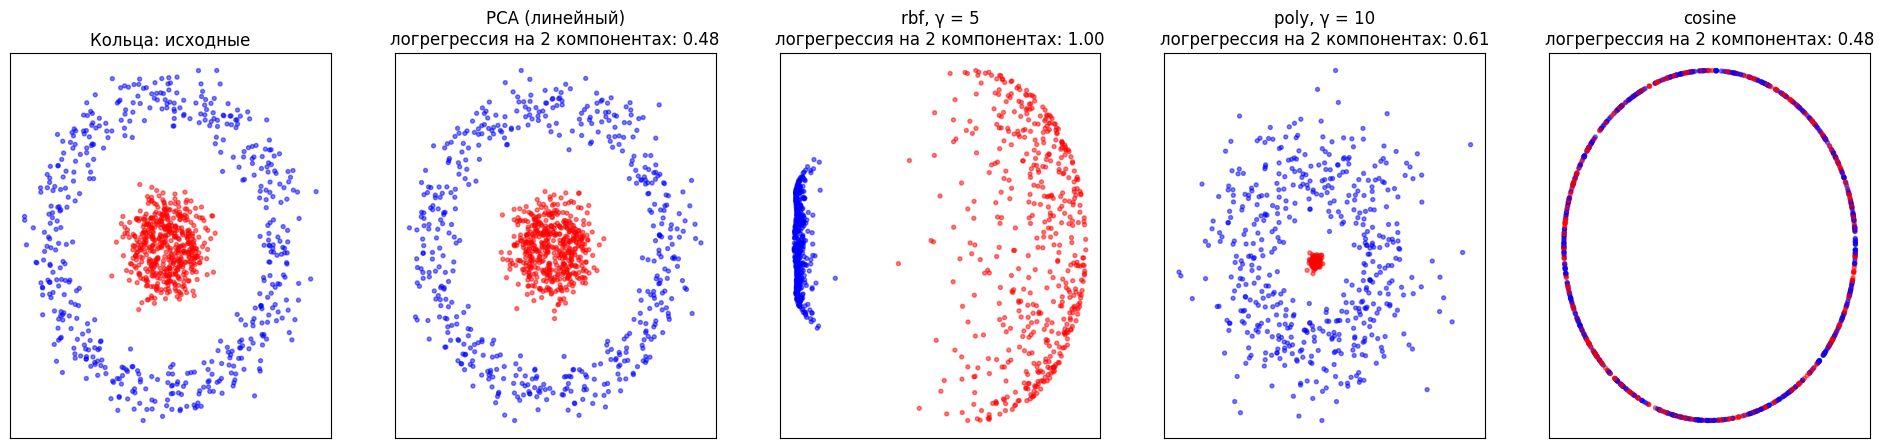

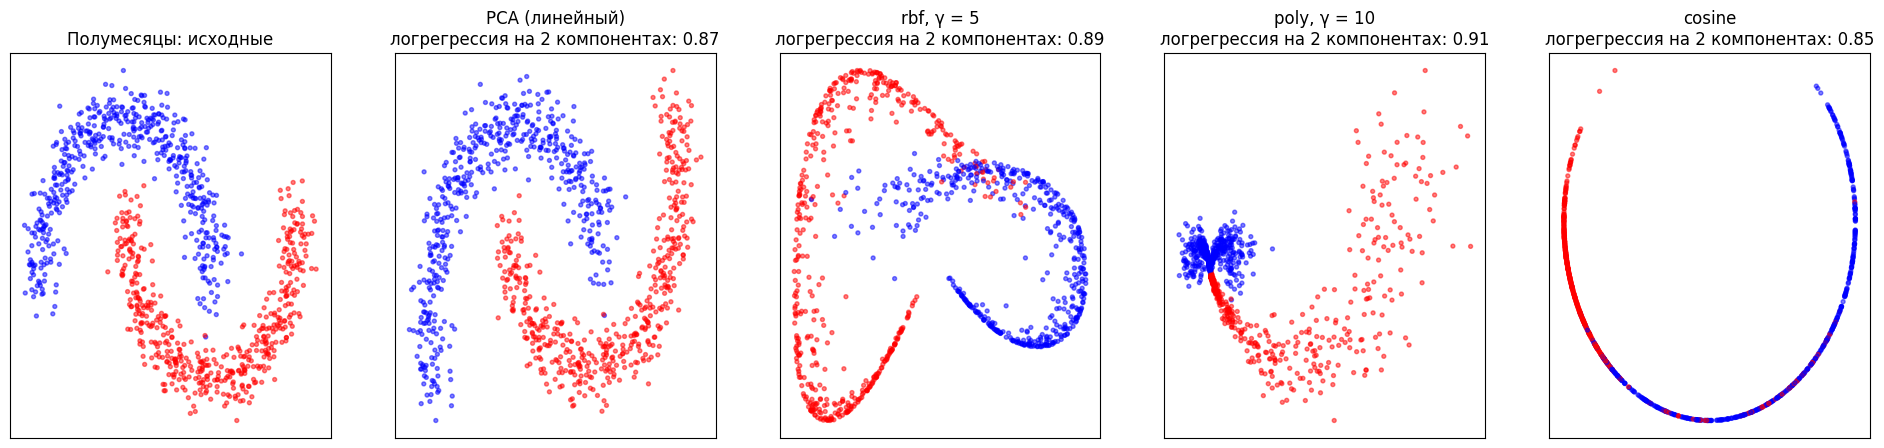

In [9]:
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import cross_val_score

def KPCA_show(X, y, title):
    methods = [('PCA (линейный)', PCA(n_components=2)),
               ('rbf, γ = 5', KernelPCA(n_components=2, kernel='rbf', gamma=5)),
               ('poly, γ = 10', KernelPCA(n_components=2, kernel='poly', gamma=10)),
               ('cosine', KernelPCA(n_components=2, kernel='cosine'))]
    fig, axes = plt.subplots(1, 5, figsize=(24, 5))
    axes[0].scatter(X[:, 0], X[:, 1], c=y, cmap='bwr', alpha=0.5, s=8)
    axes[0].set_title(f'{title}: исходные')
    for ax, (name, dec) in zip(axes[1:], methods):
        Xt = dec.fit_transform(X)
        acc = cross_val_score(LogisticRegression(), Xt, y, cv=5).mean()
        ax.scatter(Xt[:, 0], Xt[:, 1], c=y, cmap='bwr', alpha=0.5, s=8)
        ax.set_title(f'{name}\nлогрегрессия на 2 компонентах: {acc:.2f}')
    for ax in axes:
        ax.set_xticks([]); ax.set_yticks([])
    plt.show()

KPCA_show(*make_circles(n_samples=1000, factor=0.2, noise=0.1, random_state=0), 'Кольца')
KPCA_show(*make_moons(n_samples=1000, noise=0.1, random_state=0), 'Полумесяцы')

**Что мы видим.**

- **Кольца.** Обычный PCA только поворачивает плоскость: логистическая регрессия на двух компонентах даёт 0,48 — не лучше случайного. RBF-ядро разводит кольца в разные стороны, точность 1,00. Полиномиальное ядро сжимает внутреннее кольцо в маленькое пятно внутри внешнего — центр и периферия, но прямой их по-прежнему не разделить (0,61). Косинусное ядро смотрит только на направление вектора и теряет расстояние до центра — точки обоих колец ложатся на одну окружность (0,48).
- **Полумесяцы.** Здесь все варианты дают 0,85–0,91: полумесяцы и так почти разделимы прямой, а ни одно ядро с этими параметрами не «распрямляет» их полностью. Ядро и его параметры нужно подбирать под данные.

**Вопрос.** Почему RBF-ядро разделяет кольца, а обычный PCA — нет?

<details>
<summary><b>Показать ответ</b></summary>

Обычный PCA — это поворот плоскости (и, может быть, отражение): кольца остаются кольцами, и прямая их не разделит. RBF-ядро измеряет похожесть точек через расстояние между ними: $\exp(-\gamma \lVert x - x' \rVert^2)$. Точки внутреннего кольца все близки друг к другу и похожи; точки внешнего кольца далеко от внутренних. В пространстве $\varphi(x)$, которое задаёт ядро, компонента с наибольшей «дисперсией» отделяет плотное внутреннее кольцо от внешнего, и классы расходятся вдоль первой оси.

Важно: результат сильно зависит от $\gamma$. При слишком маленьком $\gamma$ все точки «похожи» друг на друга, при слишком большом каждая точка похожа только на себя. Подбирать ядро и его параметры приходится по качеству итоговой задачи.

</details>

Посмотрим на три компоненты RBF-ядра в 3D: внутреннее кольцо «поднимается» над внешним.

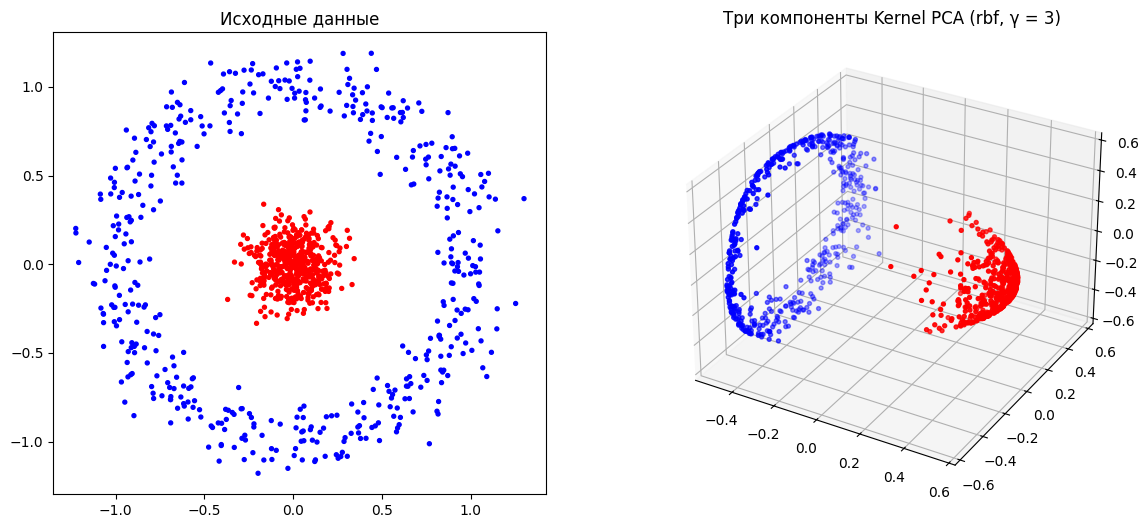

In [10]:
X_c, y_c = make_circles(n_samples=1000, factor=0.1, noise=0.1, random_state=0)
X_3d = KernelPCA(n_components=3, kernel='rbf', gamma=3).fit_transform(X_c)

fig = plt.figure(figsize=(14, 6))
ax1 = fig.add_subplot(1, 2, 1)
ax1.scatter(X_c[:, 0], X_c[:, 1], c=y_c, cmap='bwr', s=8); ax1.set_aspect('equal'); ax1.set_title('Исходные данные')
ax2 = fig.add_subplot(1, 2, 2, projection='3d')
ax2.scatter3D(X_3d[:, 0], X_3d[:, 1], X_3d[:, 2], c=y_c, cmap='bwr', s=8); ax2.set_title('Три компоненты Kernel PCA (rbf, γ = 3)')
plt.show()

## 4. t-SNE

t-SNE — нелинейный метод **визуализации**. Он старается сохранить локальное соседство: точки, близкие в исходном пространстве, должны остаться близкими на плоскости. Как он работает (подробнее — на лекции):

1. для каждой пары точек в исходном пространстве считается сходство $p_{ij}$ — гауссово, с шириной, подобранной так, чтобы у каждой точки было примерно `perplexity` «эффективных соседей»;
2. на плоскости сходства $q_{ij}$ считаются по распределению Стьюдента с тяжёлыми хвостами;
3. координаты на плоскости подбираются градиентным спуском, чтобы $q_{ij}$ были похожи на $p_{ij}$.

Возьмём те же цифры Digits, что в первой части.

(1797, 64)


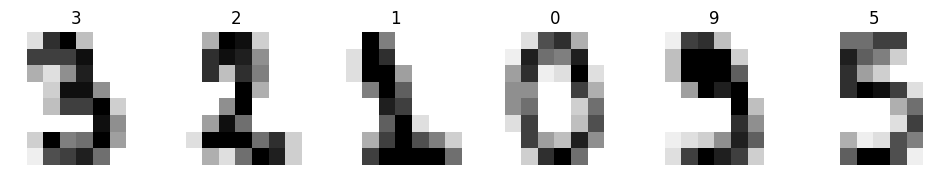

In [11]:
from sklearn.manifold import TSNE

digits = load_digits()
X, y = digits.data, digits.target
print(X.shape)

rng = np.random.default_rng(0)
idx = rng.choice(len(X), size=6, replace=False)
fig, axes = plt.subplots(1, 6, figsize=(12, 2.5))
for ax, i in zip(axes, idx):
    ax.imshow(X[i].reshape(8, 8), cmap='gray_r'); ax.set_title(y[i]); ax.axis('off')
plt.show()

### 4.1 t-SNE против PCA

t-SNE: 7.9 с
PCA:   0.006 с


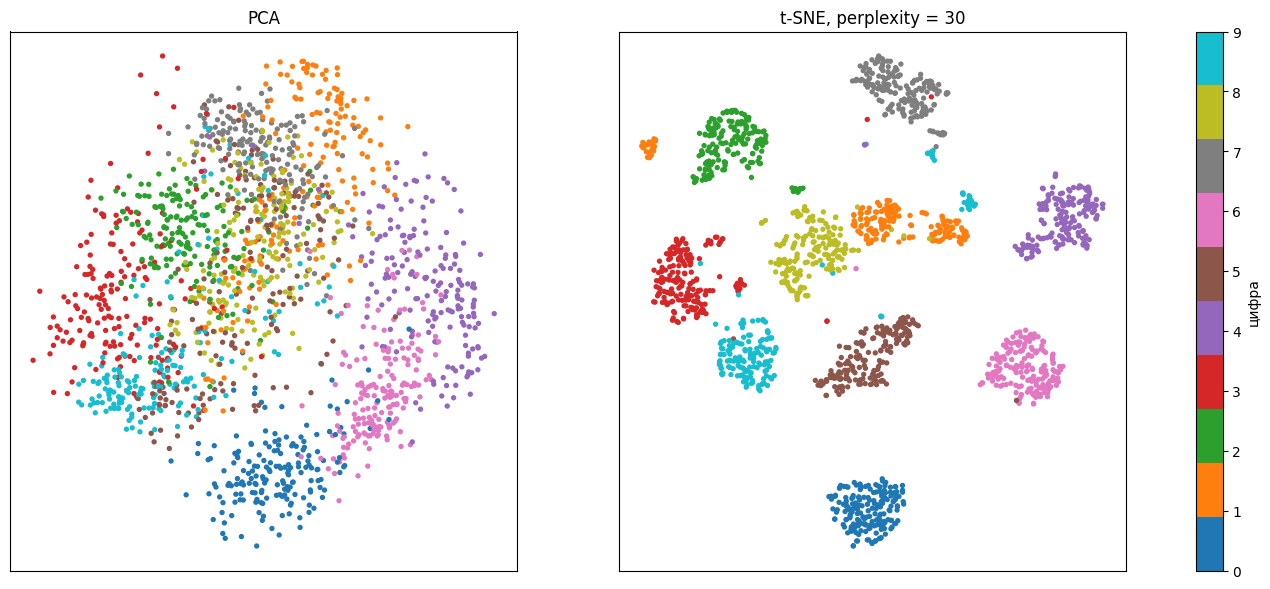

In [12]:
import time

start = time.time()
X_tsne = TSNE(n_components=2, random_state=42).fit_transform(X)
print(f't-SNE: {time.time() - start:.1f} с')
start = time.time()
X_pca = PCA(n_components=2).fit_transform(X)
print(f'PCA:   {time.time() - start:.3f} с')

fig, axes = plt.subplots(1, 2, figsize=(18, 7))
for ax, (Z, name) in zip(axes, [(X_pca, 'PCA'), (X_tsne, 't-SNE, perplexity = 30')]):
    sc = ax.scatter(Z[:, 0], Z[:, 1], c=y, cmap='tab10', s=8)
    ax.set_title(name); ax.set_xticks([]); ax.set_yticks([])
fig.colorbar(sc, ax=axes, ticks=range(10), label='цифра')
plt.show()

**Что мы видим.** На проекции PCA чётко отделяются только 0, 4 и 6, остальные цифры сильно перекрываются: две линейные компоненты сохраняют 28,5 % дисперсии. t-SNE раскладывает почти все цифры в отдельные компактные группы. Заметны и «ошибки»: часть единиц образует отдельный маленький кластер, а несколько маленьких групп девяток (голубые) оказались отдельно от основной группы, рядом с семёрками и единицами — это девятки, написанные похоже на другие цифры. Цена — время: t-SNE работал около 5 секунд, PCA — тысячные доли секунды.

Нарисуем t-SNE с картинками самих цифр, чтобы увидеть, какие объекты оказались рядом.

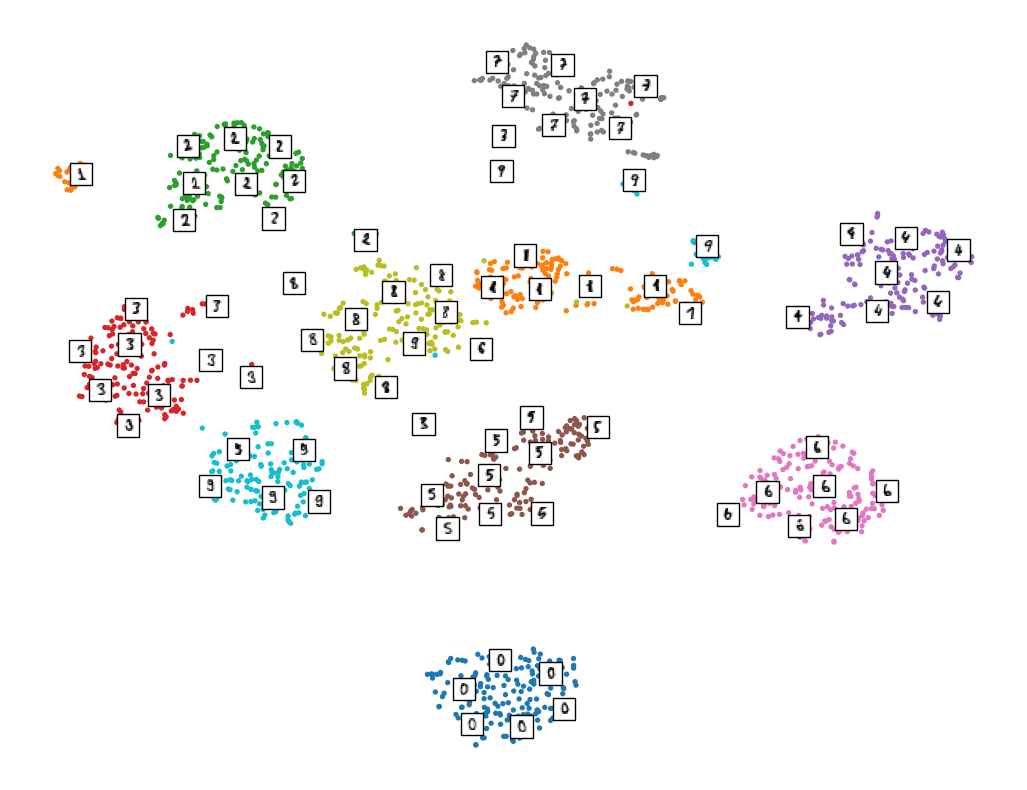

In [13]:
from sklearn.preprocessing import MinMaxScaler
from matplotlib.offsetbox import AnnotationBbox, OffsetImage

def plot_digits(Z, y, images, min_distance=0.05, figsize=(13, 10)):
    Z = MinMaxScaler().fit_transform(Z)
    cmap = plt.get_cmap('tab10')
    plt.figure(figsize=figsize)
    plt.scatter(Z[:, 0], Z[:, 1], c=[cmap(d) for d in y], s=8)
    ax = plt.gca(); ax.axis('off')
    shown = np.array([[10.0, 10.0]])
    for i, z in enumerate(Z):            # показываем картинку, если рядом ещё нет другой
        if np.linalg.norm(shown - z, axis=1).min() > min_distance:
            shown = np.vstack([shown, z])
            ax.add_artist(AnnotationBbox(OffsetImage(images[i].reshape(8, 8), cmap='binary'), z))
    plt.show()

plot_digits(X_tsne, y, X)

### 4.2 Роль perplexity и случайного старта

Верхний ряд — разная perplexity. Нижний — случайная начальная расстановка точек (`init='random'`) с разными зёрнами. По умолчанию `sklearn` начинает с проекции PCA (`init='pca'`), и картинки от запуска к запуску почти не меняются; со случайным стартом разница видна сразу.

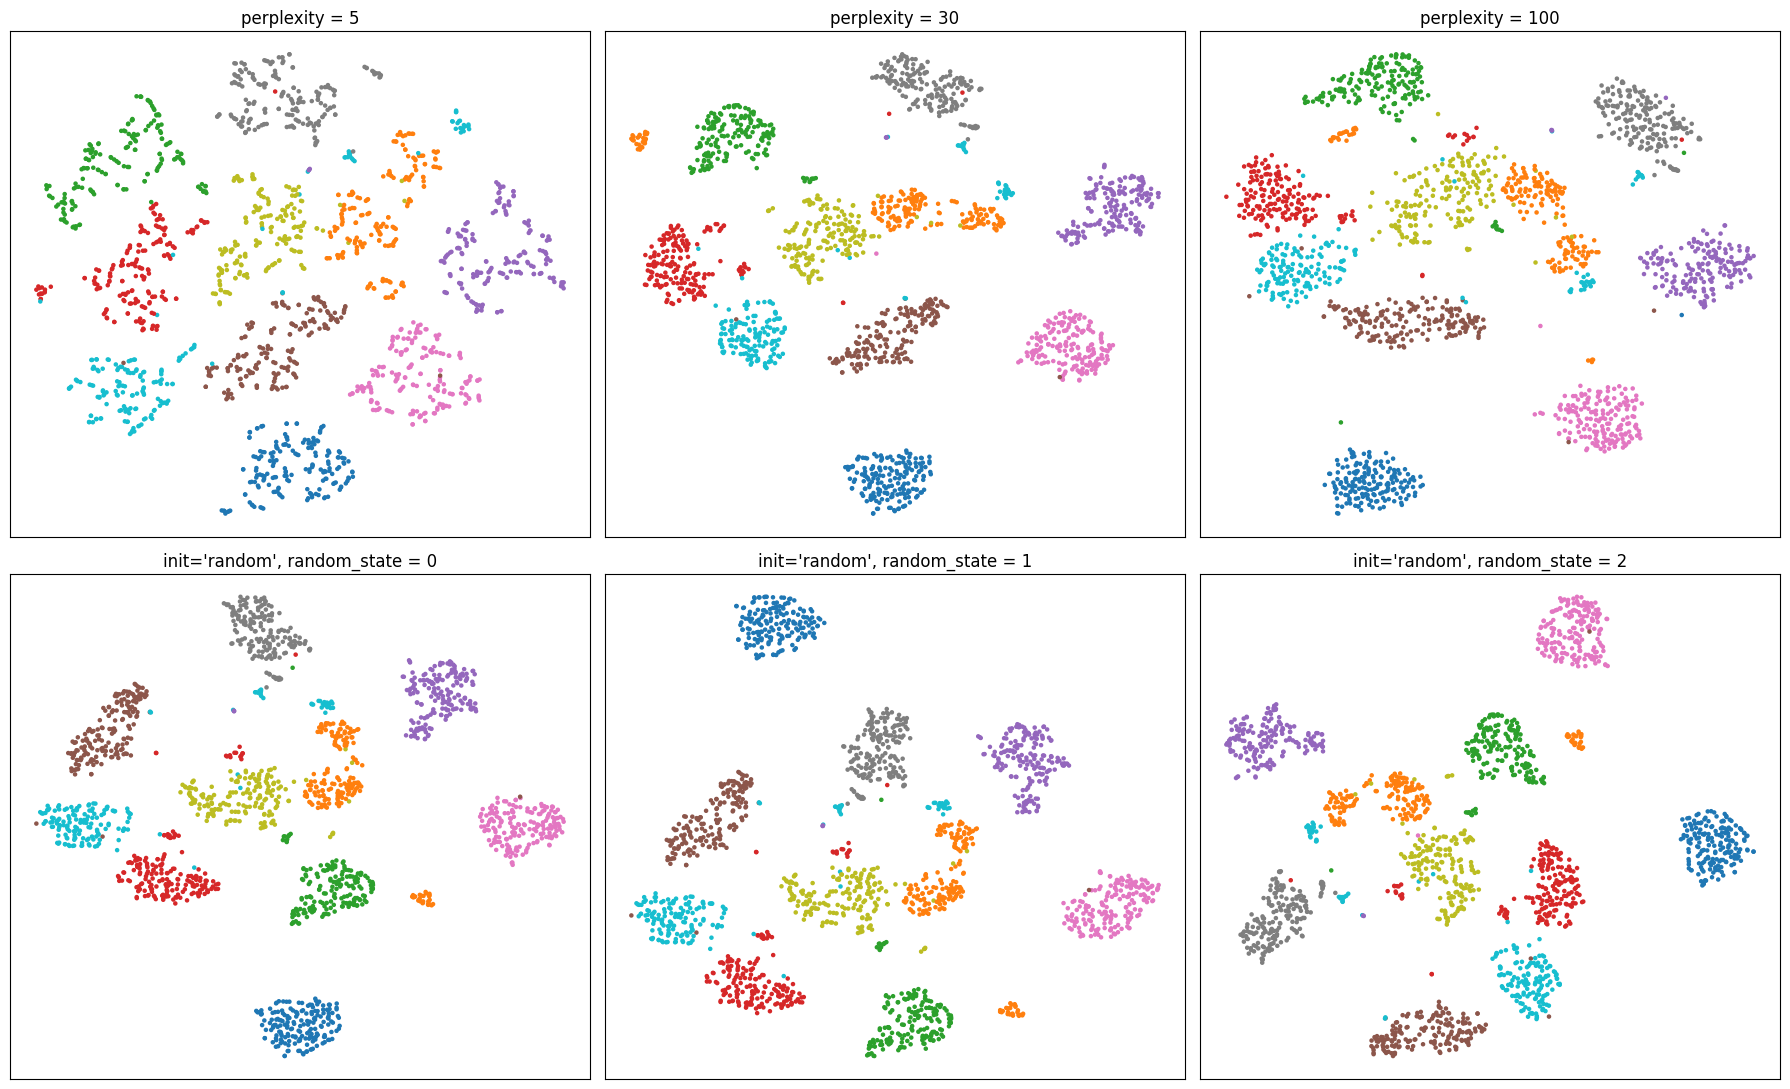

In [14]:
fig, axes = plt.subplots(2, 3, figsize=(18, 11))
for ax, p in zip(axes[0], [5, 30, 100]):
    Z = TSNE(n_components=2, perplexity=p, random_state=42).fit_transform(X)
    ax.scatter(Z[:, 0], Z[:, 1], c=y, cmap='tab10', s=5); ax.set_title(f'perplexity = {p}')
for ax, seed in zip(axes[1], [0, 1, 2]):
    Z = TSNE(n_components=2, perplexity=30, init='random', random_state=seed).fit_transform(X)
    ax.scatter(Z[:, 0], Z[:, 1], c=y, cmap='tab10', s=5); ax.set_title(f"init='random', random_state = {seed}")
for ax in axes.ravel():
    ax.set_xticks([]); ax.set_yticks([])
plt.tight_layout(); plt.show()

**Вопрос.** Что меняется на картинке при изменении perplexity и random_state? Какие выводы по картинке t-SNE устойчивы, а какие нет?

<details>
<summary><b>Показать ответ</b></summary>

При маленькой perplexity (5) каждая точка «смотрит» лишь на несколько ближайших соседей: кластеры рассыпаются на мелкие клочки и тонкие цепочки. При perplexity 30–100 учитываются более крупные окрестности, и группы цифр становятся цельными. При смене случайного старта кластеры оказываются в других местах и могут поменяться местами, а их взаимное расположение меняется.

Устойчиво то, что повторяется при разных параметрах: какие точки попадают в одну группу и какие цифры выделяются отдельно. Неустойчиво — положение групп на плоскости, расстояния между ними и их форма. Поэтому по t-SNE не делают выводов вроде «семёрки ближе к единицам, чем к нулям»; при выводах о кластерах проверяют несколько значений perplexity и несколько запусков.

</details>

### 4.3 Размеры кластеров на картинке t-SNE ничего не значат

Сгенерируем два облака по 300 точек в 10-мерном пространстве: одно плотное (стандартное отклонение 1), другое в 10 раз шире.

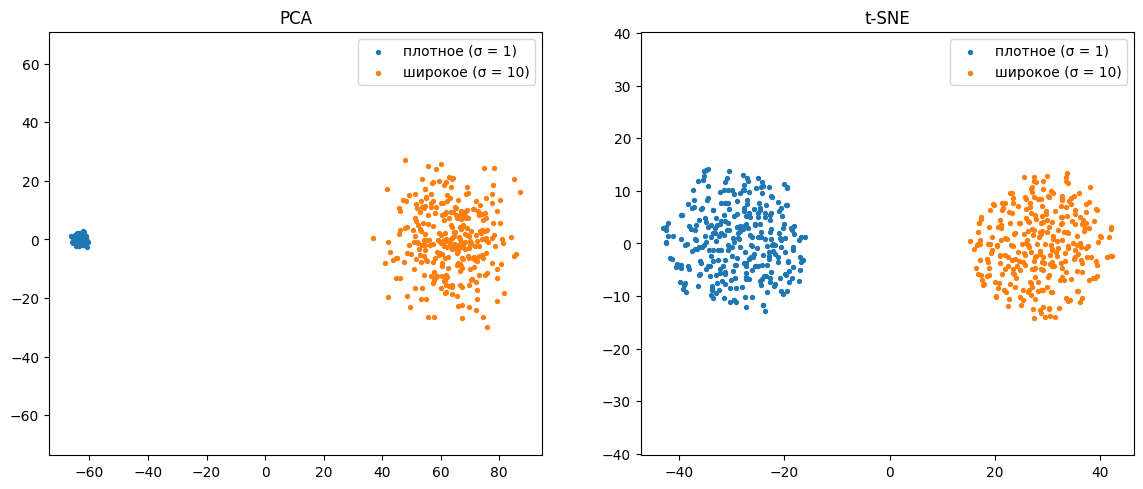

PCA: отношение разброса широкого облака к плотному = 11.0
t-SNE: отношение разброса широкого облака к плотному = 1.0


In [15]:
X_two, y_two = make_blobs(n_samples=[300, 300], n_features=10, centers=[np.zeros(10), np.full(10, 40.0)],
                          cluster_std=[1, 10], random_state=0)
Z_two = TSNE(n_components=2, random_state=0).fit_transform(X_two)
P_two = PCA(n_components=2).fit_transform(X_two)

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
for ax, (Z, name) in zip(axes, [(P_two, 'PCA'), (Z_two, 't-SNE')]):
    for c, label in zip([0, 1], ['плотное (σ = 1)', 'широкое (σ = 10)']):
        ax.scatter(Z[y_two == c, 0], Z[y_two == c, 1], s=8, label=label)
    ax.set_aspect('equal', adjustable='datalim'); ax.set_title(name); ax.legend()
plt.show()

for name, Z in [('PCA', P_two), ('t-SNE', Z_two)]:
    spread = [Z[y_two == c].std(axis=0).mean() for c in (0, 1)]
    print(f'{name}: отношение разброса широкого облака к плотному = {spread[1] / spread[0]:.1f}')

**Вопрос.** Почему у t-SNE облака получились почти одного размера, хотя в исходных данных одно в 10 раз шире другого?

<details>
<summary><b>Показать ответ</b></summary>

t-SNE подбирает ширину гауссианы для каждой точки отдельно так, чтобы у всех было примерно одинаковое число «эффективных соседей» (perplexity). В плотном облаке гауссианы узкие, в широком — широкие, и в итоге сходства $p_{ij}$ внутри обоих облаков получаются похожими. Метод сохраняет, кто чей сосед, но не абсолютные расстояния, поэтому облака на картинке одного размера: отношение разбросов у t-SNE — 1,0, а у PCA — 11,0, почти как в данных. Вывод: размер кластера на картинке t-SNE ничего не говорит о его разбросе в исходных данных.

</details>

**Вопрос.** Можно ли использовать координаты t-SNE как признаки для классификатора, обученного на одной выборке и применяемого к новым данным?

<details>
<summary><b>Показать ответ</b></summary>

Нет. У `TSNE` в `sklearn` нет метода `transform`: алгоритм не строит отображение из исходного пространства на плоскость, а подбирает координаты конкретных точек. Чтобы отобразить новый объект, пришлось бы пересчитать всю картинку заново, и она получилась бы другой. Кроме того, расстояния между далёкими точками и размеры кластеров на картинке не имеют смысла (раздел 4.3). t-SNE — инструмент для того, чтобы **посмотреть** на данные. Для предобработки признаков используют PCA, Kernel PCA или другие методы с `transform`.

</details>

## 5. Выводы

1. PCA находит оси эллиптического облака и не зависит от его поворота. Для колец, полумесяцев и кластеров его направления мало что говорят о структуре.
2. На изображениях PCA работает хорошо: соседние пиксели коррелированы, и сотни компонент вместо тысяч пикселей сохраняют почти всю информацию. Это ускоряет обучение без потери качества.
3. PCA — часть модели: при оценке качества он должен обучаться внутри кросс-валидации (`Pipeline`), иначе будет утечка.
4. Kernel PCA делает PCA в неявном пространстве признаков, заданном ядром. Удачное ядро делает нелинейную структуру линейной; ядро и его параметры приходится подбирать.
5. t-SNE хорошо показывает кластеры, но это только визуализация: картинка зависит от perplexity и случайного старта, размеры кластеров и расстояния между ними ничего не значат, новых объектов он не отображает.